# Phase 4 — Destination Research

**Main objective**: add a specific branch to the graph designed to help users find the best destination based on their requirements. An initial router determines whether this branch should be executed, depending on whether the user has already specified a destination.

Once the router is executed, the branch will:

* Generate a shortlist of candidate destinations.
* Use the available MCPs to research each candidate **only when needed**. If the llm can answer using its own general knowledge, we avoid using MCPs' tools to reduce costs associated with the tokens they generate.
* Score and compare candidate destinations.
* Give a ranking to each destination based on its relevance and supporting evidence.

In [1]:
# Imports and environment setup

import os
import json
import uuid
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display, Markdown
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, ToolMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain.tools import tool, ToolRuntime
from langgraph.types import Command
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langchain_mcp_adapters.client import MultiServerMCPClient
from pydantic import BaseModel, Field

load_dotenv(override=True)

True

## *Code inherited from phase3.ipynb*

### MCPs

#### IMPORTANT: Adjustment for Windows

The following adjustment is needed when running MCP servers via stdio inside a Jupyter notebook on Windows. Jupyter's stderr stream is not a regular file, which can cause the MCP Python SDK to fail when launching the server. This workaround redirects the server's error output to DEVNULL. On macOS and Linux, no adjustment is required.

In [2]:
import sys

if sys.platform == "win32":
    import subprocess
    from functools import partial
    import langchain_mcp_adapters.sessions as mcp_sessions

    mcp_sessions.stdio_client = partial(mcp_sessions.stdio_client, errlog=subprocess.DEVNULL)
    print("Applied the Windows adjustment")
else:
    print("Not Windows, so nothing to do here")

Applied the Windows adjustment


In [3]:
mcp_client = MultiServerMCPClient({
        # "ticketlens": {
        #     "transport": "http",
        #     "url": "https://mcp.ticketlens.com/",
        # },
        # Alternative OpenMeteo MCP for testing weather tools
        # https://github.com/cyanheads/open-meteo-mcp-server
        "weather": {
            "transport": "streamable_http",
            "url": "https://open-meteo.caseyjhand.com/mcp",
        },
        "trvl": {
            "transport": "stdio",
            "command": "trvl",
            "args": ["mcp"],
        },
        "octotrip-rental-cars": {
            "transport": "http",
            "url": "https://mcp.octotrip.app/rental-cars/mcp",
        }
    }
)

tools = await mcp_client.get_tools()
print(f"Loaded {len(tools)} tools.")

weather_tools = []
ticketlens_tool_names = {"search_pois", "search_tours", "get_tour"}
ticketlens_tools = []
trvl_tool = None
rental_cars_tool = None

counter = 0

# Extract tools from each MCP
for t in tools:
    
    if t.name.startswith("openmeteo"):
        weather_tools.append(t)

    elif t.name in ticketlens_tool_names:
        ticketlens_tools.append(t)

    elif t.name == "travel":
        trvl_tool = t

    elif t.name == "search": 
        # Renamed to avoid conflicts with other MCPs
        t.name = "search_rental_cars"
        rental_cars_tool = t
    else:
        continue

    print(f"{t.name}: {t.description}")
    counter += 1

print(f"{counter} tools available for the agent.")

Loaded 13 tools.
openmeteo_search_locations: Resolve a place name to ranked coordinate matches with country, region, elevation, timezone, and population. Required prerequisite for name-based queries — all weather tools take latitude/longitude, not place names. Search by a bare place name (city, region, or landmark); never fold a qualifier into it — pass "Baoding", not "Baoding Hebei", and "Paris", not "Paris, France". To disambiguate places that share a name, set the country input (ISO 3166-1 alpha-2, e.g. "US") and/or read the admin1 and country fields on each ranked result — admin1 is a result field for choosing among matches, not a search input. Returns up to 10 matches ranked by population/relevance.
openmeteo_get_elevation: Terrain elevation from the Copernicus Digital Elevation Model (~90m resolution) for one or more coordinate pairs. Accepts up to 100 pairs per call. Useful for geographic context, elevation-adjusted weather interpretation, or route planning.
openmeteo_get_foreca

### Define the shared `TravelState`

In [4]:
# Define the shared TravelState
class TravelRequirements(BaseModel):
    origin: str | None = None
    destination: str | None = None
    travel_dates: str | None = None
    duration_days: int | None = None
    travelers: int | None = None
    budget: float | None = None
    currency: str | None = None
    interests: list[str] = Field(default_factory=list)
    constraints: list[str] = Field(default_factory=list)

class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None

#### Tool for updating the travel state

In [5]:
# Auxliary functions for update_requirements tool
def normalize_list(value: list[str] | str | None) -> list[str]:
    """
    Normalize a value into a list of strings.

    Accepts None, an existing list, or a JSON-encoded list returned as a string.
    If the string is not valid JSON, it is treated as a single list item.
    """
    if value is None:
        return []

    if isinstance(value, list):
        return value

    # The model may return the list as a JSON-encoded string.
    if isinstance(value, str):
        try:
            parsed = json.loads(value)

            # Return the parsed value if it is a valid JSON list.
            if isinstance(parsed, list):
                return parsed

        except json.JSONDecodeError:
            pass

        return [value]

    # Fallback for unexpected input types.
    return []

In [6]:
@tool
def update_requirements(
    runtime: ToolRuntime,
    origin: str | None = None,
    destination: str | None = None,
    travel_dates: str | None = None,
    duration_days: int | None = None,
    travelers: int | None = None,
    budget: float | None = None,
    currency: str | None = None,
    add_interests: list[str] | str | None = None,
    remove_interests: list[str] | str | None = None,
    add_constraints: list[str] | str | None = None,
    remove_constraints: list[str] | str | None = None,
) -> Command:
    """
    Update the user's current travel requirements.

    Only provide fields that have been explicitly added or changed by the user.

    For interests and constraints:
    - Use add_interests to add new interests.
    - Use remove_interests to remove previous interests.
    - Use add_constraints to add new constraints.
    - Use remove_constraints to remove previous constraints.

    Do not invent requirements or modify information that the user has not
    explicitly changed.
    """

    # ToolRuntime gives the tool access to the current LangGraph state,
    # including the TravelRequirements stored in the current graph execution.
    current = runtime.state["requirements"]

    if current is None:
        current = TravelRequirements()

    updated = current.model_copy()

    # Normalize list arguments in case the model sends JSON strings.
    add_interests = normalize_list(add_interests)
    remove_interests = normalize_list(remove_interests)
    add_constraints = normalize_list(add_constraints)
    remove_constraints = normalize_list(remove_constraints)

    # Update scalar fields only when explicitly provided
    if origin is not None:
        updated.origin = origin

    if destination is not None:
        updated.destination = destination

    if travel_dates is not None:
        updated.travel_dates = travel_dates

    if duration_days is not None:
        updated.duration_days = duration_days

    if travelers is not None:
        updated.travelers = travelers

    if budget is not None:
        updated.budget = budget

    if currency is not None:
        updated.currency = currency

    # Update interests
    if add_interests:
        updated.interests = list(
            dict.fromkeys(
                updated.interests + add_interests
            )
        )

    if remove_interests:
        updated.interests = [
            interest
            for interest in updated.interests
            if interest not in remove_interests
        ]

    # Update constraints
    if add_constraints:
        updated.constraints = list(
            dict.fromkeys(
                updated.constraints + add_constraints
            )
        )

    if remove_constraints:
        updated.constraints = [
            constraint
            for constraint in updated.constraints
            if constraint not in remove_constraints
        ]

    # Command tells LangGraph to update the graph state.
    # The new TravelRequirements replaces the current "requirements" value.
    return Command(
        update={
            "requirements": updated,
            "messages": [
                ToolMessage(
                    content="Travel requirements updated successfully.",
                    tool_call_id=runtime.tool_call_id,
                )
            ],
        }
    )

### Travel Planner Agent

In [7]:
SYSTEM_PROMPT = """
You are a Travel Planner specialized in helping users design personalized trips.

Your goal is to understand the user's travel preferences and constraints and
help them make informed travel decisions.

Your personality is:
- Helpful and practical
- Clear and concise
- Curious about the user's preferences
- Honest about uncertainty
- Proactive when additional information would improve the recommendation

When planning a trip:
- Consider the user's stated preferences and constraints carefully.
- Ask for clarification when essential information is missing.
- Do not invent specific facts, prices, availability, or other real-world data.
- Explain the reasoning behind important recommendations.
- Prioritize the user's requirements rather than suggesting generic popular destinations.

When updating the travel state:
- Treat the current travel requirements as the current state of the trip.
- Use the update_requirements tool when the user adds, changes, removes, or reverses a travel requirement.
- Only update information explicitly provided by the user.
- Preserve requirements that have not changed.
- If the user withdraws or contradicts a previous requirement, remove or replace the previous requirement.
- When requirements conflict, prioritize the user's latest explicit instruction.

Tools:
- Use external tools when they can provide relevant, specific information  for the user's request.
- Prefer tool results over general knowledge when answering questions that depend on external or current information.
- Do not claim that you searched for or verified information unless a tool actually returned it.
- Use the minimum number of tools necessary to answer the user's request.
- If a tool cannot provide the requested information, be transparent about the limitation rather than inventing an answer.

trvl (specific guidelines for 'travel' tool use):
- For hotel/accommodation recommendations, prefer search_accommodations over search_hotels.
- For search_accommodations, pass the known location, check_in, check_out, guests, currency and budget, and use max_candidates=5 and max_offers=5 unless the user requests a broader search.
- For flights, use intent=flights with origin, destination and departure_date. For round trips, also provide return_date. Use passengers when provided.
- Use search_hotels for broad hotel discovery when appropriate.
- For ground transport, use  intent=ground and provide from, to, date and type when known. type must be one of: train, bus, ferry.
- For rental cars, use search_rental_cars instead of 'travel' tool.

Scope:
- Only answer questions related to travel planning and your capabilities.
- If the user asks about something outside your scope, briefly explain that you cannot help with it.

When using external travel data:
- Clearly distinguish information obtained from tools from general knowledge.
- Do not assume that tool results guarantee current prices or availability unless the tool explicitly provides that information.
"""

In [8]:
def sanitize_messages_for_llm(messages):
    """
    Auxiliary function for removing file/resource blocks from ToolMessages before 
    sending them to OpenAI Chat Completions.

    This fixes the error "OpenAI Chat Completions does not support file URLs." that 
    occured passing the trvl tool's response to the LLM.

    The original messages remain unchanged in LangGraph state.
    """

    sanitized = []

    for message in messages:

        if isinstance(message, ToolMessage) and isinstance(message.content, list):

            text_blocks = []

            for block in message.content:
                if (
                    isinstance(block, dict)
                    and block.get("type") == "text"
                    and "text" in block
                ):
                    text_blocks.append(block["text"])

            if text_blocks:
                sanitized.append(
                    ToolMessage(
                        content="\n".join(text_blocks),
                        tool_call_id=message.tool_call_id,
                        name=message.name,
                    )
                )

            else:
                sanitized.append(message)

        else:
            sanitized.append(message)

    return sanitized

In [10]:
# ---- LLM Node ----
llm = ChatOpenAI(
    model="xiaomi/mimo-v2.5",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
)

# Add tools to the LLM, including the ones from MCPs
tools = [update_requirements, *ticketlens_tools, *weather_tools, trvl_tool, rental_cars_tool]
llm_with_tools = llm.bind_tools(tools)

async def llm_node(state: TravelState) -> dict:
    # Extract the current requirements from the state
    current_requirements = state["requirements"]
    requirements_context = SystemMessage(
        content=f"""
Current travel requirements:

{current_requirements}
"""
    )

    # Add the current requirements to the system prompt + messages
    messages = [
        SystemMessage(content=SYSTEM_PROMPT),
        requirements_context, 
        *sanitize_messages_for_llm(state["messages"]),
    ]

    response = await llm_with_tools.ainvoke(messages)

    return {"messages": [response]}

## Implement requirements extraction node

This node is responsible for extracting user requirements and incorporating them into the graph state. In this case, we use the same LLM as in the previous phases, but we now **reduce its reasoning effort** to obtain faster and more cost-effective responses.

In [11]:
REQUIREMENTS_EXTRACTION_PROMPT = """
Extract the user's explicit travel requirements into the provided schema.

Only include information explicitly stated by the user.
Do not infer preferences, constraints, destinations, dates, budgets, or other values.

Preserve the user's meaning when normalizing values such as dates and currency.
Leave unknown fields empty.
"""

In [ ]:
low_reasoning_llm = ChatOpenAI(
    model="xiaomi/mimo-v2.5",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),

    # OpenRouter-specific parameters
    extra_body={
        "reasoning": {
            "effort": "minimal",
        }
    },
)

requirements_llm = low_reasoning_llm.with_structured_output(
    TravelRequirements
)

async def extract_requirements(state: TravelState):
    response = await requirements_llm.ainvoke([
        SystemMessage(content=REQUIREMENTS_EXTRACTION_PROMPT),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"requirements": response}

### Test the node with different prompts

In [23]:
prompt1 = "I'm going to Paris from September 10 to September 17, 2026 for two people. My budget is €1,000."
prompt2 = "I want to travel to Japan for about two weeks in April. There will be three of us. We're interested in food and culture."
prompt3 = "Find me a beach destination in Europe for a week in July. I'm traveling alone and want to spend around €1,500."
prompt4 = "I want to visit Rome. I haven't decided the dates yet, but I'll be traveling with my partner. We prefer cultural activities and have a budget of €2,000."

In [28]:
for prompt in [prompt1, prompt2, prompt3, prompt4]:
    state = {
        "messages": [HumanMessage(content=prompt)],
        "requirements": None,
    }

    result = await extract_requirements(state)
    print(prompt)
    print(result["requirements"])
    print("-" * 80)

I'm going to Paris from September 10 to September 17, 2026 for two people. My budget is €1,000.
origin='' destination='Paris' travel_dates='2026-09-10 to 2026-09-17' duration_days=7 travelers=2 budget=1000.0 currency='EUR' interests=[] constraints=[]
--------------------------------------------------------------------------------
I want to travel to Japan for about two weeks in April. There will be three of us. We're interested in food and culture.
origin=None destination='Japan' travel_dates='April' duration_days=None travelers=3 budget=None currency=None interests=['food', 'culture'] constraints=[]
--------------------------------------------------------------------------------
Find me a beach destination in Europe for a week in July. I'm traveling alone and want to spend around €1,500.
origin='' destination='' travel_dates='' duration_days=7 travelers=1 budget=1500.0 currency='EUR' interests=[] constraints=['destination_type: beach', 'destination_region: Europe', 'duration: 1 week',

## Implement the research router

The router is implemented as an LLM call that returns only whether or not destination search mode should be enabled. Since the task is simple in this case, a **lighter model** is used to reduce costs and improve response time.

In [29]:
class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None
    destination_research_needed: bool # <-- New field

In [30]:
class ResearchDecision(BaseModel):
    needs_research: bool

In [31]:
RESEARCH_ROUTER_PROMPT = """
You are a travel-planning router.

Decide whether destination research is needed.

Set needs_research=true when the user has not committed to a single destination
and would benefit from discovering, comparing, or selecting destinations.
This includes requests that provide multiple destinations and ask to compare
or choose between them.

Set needs_research=false only when the user has clearly chosen one specific
destination, even if they want to research hotels, flights, activities, or
other options there.

Base the decision only on the user's request. Do not invent requirements.
"""

In [32]:
light_llm = ChatOpenAI(
    model="google/gemma-3-12b-it",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
)

structured_router_llm = light_llm.with_structured_output(ResearchDecision)

async def research_router(state: TravelState):
    response = await structured_router_llm.ainvoke([
        SystemMessage(content=RESEARCH_ROUTER_PROMPT),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"destination_research_needed": response.needs_research}

### Check if the router decides correctly

In [15]:
async def test_router(prompt: str):
    state = {
        "messages": [HumanMessage(content=prompt)],
        "requirements": None,
        "destination_research_needed": False,
    }

    result = await research_router(state)

    print(f"Prompt: {prompt}")
    print(f"needs_research: {result['destination_research_needed']}")

In [16]:
await test_router(
    "I want to travel somewhere in Europe in September. "
    "Find me some good destinations for food and culture."
) # True

await test_router(
    "I'm going to Paris in September. Find me suitable hotels for two people."
) # False

await test_router(
    "Compare Paris, Rome and Barcelona for a week-long trip in September "
    "and tell me which one is best."
) # True

Prompt: I want to travel somewhere in Europe in September. Find me some good destinations for food and culture.
needs_research: True
Prompt: I'm going to Paris in September. Find me suitable hotels for two people.
needs_research: False
Prompt: Compare Paris, Rome and Barcelona for a week-long trip in September and tell me which one is best.
needs_research: True


## Implement destination research node

In [51]:
class DestinationCandidate(BaseModel):
    destination: str
    reason: str

class DestinationResearchResult(BaseModel):
    candidates: list[DestinationCandidate]

In [52]:
DESTINATION_RESEARCH_PROMPT = """
You are the destination discovery step of a travel planner.

Generate a shortlist of 3-5 destinations that best match the user's travel
requirements.

Use only the requirements explicitly provided by the user. Do not invent
preferences or constraints.

Prefer diverse, realistic candidates rather than several very similar options.
Do not research or provide specific prices, availability, hotels, flights, or
activities. This step only generates candidate destinations.

For each destination, give a brief reason why it matches the requirements.
"""

In [53]:
destination_llm = llm.with_structured_output(DestinationResearchResult)

async def destination_research(state: TravelState):
    requirements = state["requirements"]

    response = await destination_llm.ainvoke([
        SystemMessage(content=DESTINATION_RESEARCH_PROMPT),
        SystemMessage(content=f"Current travel requirements:\n{requirements}"),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {
        "destination_candidates": response.candidates
    }

### Add new conditional edge to the graph

In [54]:
def route_destination_research(state: TravelState):
    if state["destination_research_needed"]:
        return "destination_research"
    return "llm"

### Graph Builder

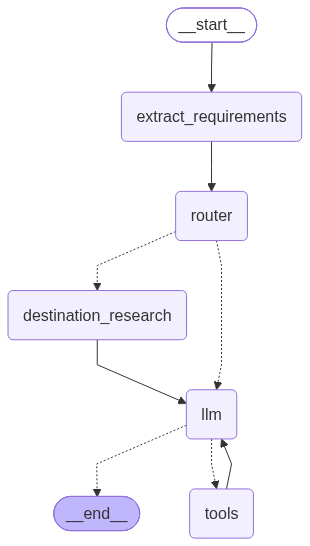

In [57]:
# Add short-term memory checkpointing
checkpointer = InMemorySaver()

builder = StateGraph(TravelState)

# ---- Nodes ----
builder.add_node("extract_requirements", extract_requirements)
builder.add_node("router", research_router)
builder.add_node("destination_research", destination_research)
builder.add_node("llm", llm_node)
builder.add_node("tools", ToolNode(tools))

# ---- Edges ----
builder.add_edge(START, "extract_requirements")
builder.add_edge("extract_requirements", "router")

builder.add_conditional_edges(
    "router",
    route_destination_research,
    {
        "destination_research": "destination_research",
        "llm": "llm",
    },
)

builder.add_edge("destination_research", "llm")

builder.add_conditional_edges("llm", tools_condition)
builder.add_edge("tools", "llm")

# ---- Compile ----
graph = builder.compile(checkpointer=checkpointer)

display(Image(graph.get_graph().draw_mermaid_png()))